# Función de desempeño de seguridad (FDS) para siniestralidad peatonal en Bogotá
### Poisson / Binomial Negativa / ZINB por segmento vial, con validación aleatoria y por bloques espaciales (v4)

**Correcciones incorporadas:** verificación de la BN y dispersión, regla de decisión declarada, diagnósticos de ajuste, errores estándar robustos, Moran de residuales y validación por bloques espaciales.

## 1. Entorno y parámetros

In [1]:
## Librerías
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
import sklearn
from scipy import stats
from scipy.optimize import minimize_scalar
from scipy.sparse import csr_matrix, diags
from scipy.spatial import cKDTree
from scipy.special import expit
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error, mean_squared_error
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.max_columns', 80)

In [2]:
## Parámetros del análisis (todo lo que se ajusta a mano está aquí)
SEMILLA = 1949
K_PLIEGUES = 5
LONGITUD_LIBRE = False        # False: offset log(longitud) como en la metodología; True: log(longitud) como covariable
COL_X, COL_Y = 'x_m', 'y_m'   # centroide del segmento en EPSG:3116
TAM_BLOQUE_M = 2000           # lado de la celda de la validación por bloques; se contrasta con el correlograma (sección 8)
K_VECINOS = 8                 # vecinos para la matriz de pesos del I de Moran
N_PERM = 199                  # permutaciones para el p-valor del I de Moran

print(f"Python: {sys.version.split()[0]} | statsmodels: {statsmodels.__version__} | scikit-learn: {sklearn.__version__} | pandas: {pd.__version__}")

Python: 3.13.7 | statsmodels: 0.14.6 | scikit-learn: 1.9.0 | pandas: 3.0.5


## 2. Datos, offset y covariables

In [3]:
## Carga del conjunto unificado; el índice queda 0..n-1 porque las particiones trabajan por posición
df_unificado = pd.read_csv('Data/processed/segmentos_unificado.csv').reset_index(drop=True)

In [4]:
## Verificación de columnas, de la variable respuesta y de las coordenadas
COL_DIST = ['dist_puente_peatonal_m', 'dist_puente_vehicular_m', 'dist_semaforo_m', 'ratio_cobertura_peatonal']
COLS_REQ = COL_DIST + ['MVINUMC', 'MVI_VELREG', 'long_seg_m', 'n_siniestros', COL_X, COL_Y]

faltan = [c for c in COLS_REQ if c not in df_unificado.columns]
assert not faltan, f'Faltan columnas: {faltan} (las coordenadas se crean en el cuaderno de unión con el centroide de cada segmento)'
assert df_unificado[COLS_REQ].notna().all().all(), 'Hay valores faltantes en las columnas del modelo'
assert (df_unificado['long_seg_m'] > 0).all(), 'Hay segmentos con longitud no positiva'

print(f"Segmentos: {len(df_unificado)} | % con cero siniestros: {100 * (df_unificado['n_siniestros'] == 0).mean():.2f}")
print(df_unificado['n_siniestros'].value_counts().sort_index().head(8).to_string())

Segmentos: 131704 | % con cero siniestros: 89.88
n_siniestros
0    118382
1      9826
2      2062
3       729
4       332
5       147
6        85
7        41


In [5]:
## Respuesta, log-longitud y covariables: log1p en distancias (se estandarizan por pliegue) y dummies de velocidad
Y_ALL = df_unificado['n_siniestros'].to_numpy(float)
OFF_LEN = np.log(df_unificado['long_seg_m'].to_numpy(float))
XY = df_unificado[[COL_X, COL_Y]].to_numpy(float)

X0 = df_unificado[COL_DIST + ['MVINUMC']].copy()
X0[COL_DIST] = np.log1p(X0[COL_DIST])
DUM = pd.get_dummies(df_unificado['MVI_VELREG'].astype(int).astype(str), prefix='vel', drop_first=True, dtype=float)


def armar_disenio(pos_tr, pos_te, libre=False):
    ## Matrices del conteo (X) y de la inflación (Xi); el escalador y la media de log-longitud usan solo entrenamiento
    esc = StandardScaler().fit(X0.iloc[pos_tr][COL_DIST])
    mu_l, sd_l = OFF_LEN[pos_tr].mean(), OFF_LEN[pos_tr].std()

    def _X(pos):
        X = X0.iloc[pos].copy()
        X[COL_DIST] = esc.transform(X[COL_DIST])
        if libre:
            X['log_long'] = OFF_LEN[pos] - mu_l    # su coeficiente es la elasticidad con la longitud
        return sm.add_constant(pd.concat([X, DUM.iloc[pos]], axis=1), has_constant='add')

    def _Xi(pos, X):
        return pd.DataFrame({'const': 1.0, 'log_long_z': (OFF_LEN[pos] - mu_l) / sd_l}, index=X.index)

    X_tr, X_te = _X(pos_tr), _X(pos_te)
    off_tr, off_te = (np.zeros(len(pos_tr)), np.zeros(len(pos_te))) if libre else (OFF_LEN[pos_tr], OFF_LEN[pos_te])
    return dict(X_tr=X_tr, X_te=X_te, Xi_tr=_Xi(pos_tr, X_tr), Xi_te=_Xi(pos_te, X_te),
                off_tr=off_tr, off_te=off_te, len_tr=OFF_LEN[pos_tr], len_te=OFF_LEN[pos_te],
                y_tr=Y_ALL[pos_tr], y_te=Y_ALL[pos_te])


def entradas(m, D, parte):
    ## Devuelve (y, X, offset, Xi) de 'tr' o 'te'; el modelo nulo siempre usa log(longitud) como offset
    off = D['len_' + parte] if m['tipo'] == 'nulo' else D['off_' + parte]
    return D['y_' + parte], D['X_' + parte], off, D['Xi_' + parte]

## 3. Modelos candidatos

In [6]:
## Alpha de la BN por perfil de verosimilitud: se maximiza el logLik del GLM sobre log(alpha); no depende del optimizador de NegativeBinomial
def alpha_perfil(y, X, off):
    def nll(t):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            return -sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=np.exp(t)), offset=off).fit().llf

    r = minimize_scalar(nll, bounds=(np.log(1e-4), np.log(50)), method='bounded', options={'xatol': 1e-4})
    return float(np.exp(r.x)), r


## Ajuste en cadena de optimizadores (solo para el ZINB y para contrastar la BN de statsmodels); maxiter explícito
def _num(a):
    return np.asarray(a, dtype=float)


def _fit_robusto(modelo, start=None, plan=(('bfgs', 500), ('lbfgs', 1000), ('nm', 4000))):
    mejor, ok = None, False
    for metodo, it in plan:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            try:
                r = modelo.fit(start_params=start, method=metodo, maxiter=it, disp=0)
            except Exception:
                continue
        p = _num(r.params)
        if not np.all(np.isfinite(p)):
            continue
        conv = bool(r.mle_retvals.get('converged', False))
        if mejor is None or conv or r.llf > mejor.llf:
            mejor, ok = r, conv
        if conv:
            break
        start = p
    if mejor is None:
        raise RuntimeError('Ningún optimizador devolvió parámetros finitos')
    return mejor, ok

In [7]:
## Los cuatro modelos con la misma interfaz: media, logpmf, cdf, parámetros, AIC, BIC y convergencia
def ajustar(tipo, y, X, off, len_, Xi=None, params_bn=None):
    y, off, res, alpha, pi = _num(y), _num(off), None, np.nan, None

    if tipo == 'nulo':
        b0 = np.log(y.sum() / np.exp(_num(len_)).sum())    # MLE cerrado de Poisson solo con intercepto y offset de longitud
        media = lambda X, off, Xi=None: np.exp(b0 + _num(off))
        logpmf = lambda y, X, off, Xi=None: stats.poisson.logpmf(_num(y), media(X, off))
        cdf = lambda y, X, off, Xi=None: stats.poisson.cdf(_num(y), media(X, off))
        params, ok, off_ev = np.array([b0]), True, _num(len_)

    elif tipo == 'poisson':
        res = sm.GLM(y, X, family=sm.families.Poisson(), offset=off).fit()
        params, ok, off_ev = _num(res.params), bool(res.converged), off
        media = lambda X, off, Xi=None: np.exp(np.clip(_num(X) @ params + _num(off), -30, 30))
        logpmf = lambda y, X, off, Xi=None: stats.poisson.logpmf(_num(y), media(X, off))
        cdf = lambda y, X, off, Xi=None: stats.poisson.cdf(_num(y), media(X, off))

    elif tipo == 'bn':
        alpha, r_opt = alpha_perfil(y, X, off)
        res = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha), offset=off).fit()
        params, ok, off_ev = np.r_[_num(res.params), alpha], bool(res.converged and r_opt.success), off
        b = params[:-1]
        media = lambda X, off, Xi=None: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
        # NB2: n = 1/alpha y p = 1/(1 + alpha*mu) dan media mu y varianza mu + alpha*mu^2
        logpmf = lambda y, X, off, Xi=None: stats.nbinom.logpmf(_num(y), 1 / alpha, 1 / (1 + alpha * media(X, off)))
        cdf = lambda y, X, off, Xi=None: stats.nbinom.cdf(_num(y), 1 / alpha, 1 / (1 + alpha * media(X, off)))

    else:
        k_inf = Xi.shape[1]
        mod = ZeroInflatedNegativeBinomialP(y, X, exog_infl=Xi, offset=off, inflation='logit', p=2)
        start = np.r_[-3.0, np.zeros(k_inf - 1), _num(params_bn)] if params_bn is not None else None
        res, ok = _fit_robusto(mod, start)
        params, off_ev = _num(res.params), off                  # orden de statsmodels: [inflación, conteo, alpha]
        g, b, alpha = params[:k_inf], params[k_inf:-1], max(params[-1], 1e-8)
        mu = lambda X, off: np.exp(np.clip(_num(X) @ b + _num(off), -30, 30))
        pi = lambda Xi: expit(_num(Xi) @ g)
        media = lambda X, off, Xi: (1 - pi(Xi)) * mu(X, off)

        def logpmf(y, X, off, Xi):
            y_, m_, p_ = _num(y), mu(X, off), pi(Xi)
            lnb = stats.nbinom.logpmf(y_, 1 / alpha, 1 / (1 + alpha * m_))
            with np.errstate(divide='ignore'):
                return np.where(y_ == 0, np.logaddexp(np.log(p_), np.log1p(-p_) + lnb), np.log1p(-p_) + lnb)

        def cdf(y, X, off, Xi):
            y_, m_, p_ = _num(y), mu(X, off), pi(Xi)
            return np.where(y_ < 0, 0.0, p_ + (1 - p_) * stats.nbinom.cdf(y_, 1 / alpha, 1 / (1 + alpha * m_)))

    n, k = len(y), len(params)
    llf = float(logpmf(y, X, off_ev, Xi).sum())
    if res is not None and abs(res.llf - llf) > 1e-3 * abs(res.llf) + 1e-2:
        warnings.warn(f'{tipo}: llf propio ({llf:.2f}) != llf de statsmodels ({res.llf:.2f})', RuntimeWarning)
    return dict(tipo=tipo, res=res, media=media, logpmf=logpmf, cdf=cdf, params=params, k=k, llf=llf,
                aic=-2 * llf + 2 * k, bic=-2 * llf + k * np.log(n), convergio=ok, alpha=alpha, pi=pi)


def ajustar_todos(D, con_zinb=True):
    ## El ZINB arranca desde los parámetros de la BN
    args = (D['y_tr'], D['X_tr'], D['off_tr'], D['len_tr'])
    m = {'Nulo': ajustar('nulo', *args), 'Poisson': ajustar('poisson', *args), 'BN': ajustar('bn', *args)}
    if con_zinb:
        m['ZINB'] = ajustar('zinb', *args, D['Xi_tr'], params_bn=m['BN']['params'])
    return m


def metricas(m, D):
    y, X, off, Xi = entradas(m, D, 'te')
    mu = np.clip(m['media'](X, off, Xi), 1e-9, None)
    return dict(MAE=mean_absolute_error(y, mu), RMSE=float(np.sqrt(mean_squared_error(y, mu))),
                devianza=mean_poisson_deviance(y, mu), logscore=float(m['logpmf'](y, X, off, Xi).mean()))


def rqr(m, D, parte, semilla=SEMILLA):
    ## Residuos cuantílicos aleatorizados (Dunn y Smyth, 1996): N(0,1) si el modelo es correcto, sirven para cualquier conteo
    y, X, off, Xi = entradas(m, D, parte)
    lo, hi = m['cdf'](y - 1, X, off, Xi), m['cdf'](y, X, off, Xi)
    u = np.random.default_rng(semilla).uniform(lo, hi)
    return stats.norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))

## 4. Ajuste con todos los segmentos

In [8]:
## Ajuste con todos los segmentos; el ZINB usa inflación logit(pi) = g0 + g1*log-longitud estandarizada
pos_all = np.arange(len(df_unificado))
D = armar_disenio(pos_all, pos_all, libre=LONGITUD_LIBRE)
aj = ajustar_todos(D)

comp = pd.DataFrame([dict(modelo=nom, parametros=m['k'], logLik=m['llf'], AIC=m['aic'], BIC=m['bic'], alpha=m['alpha'],
                          pi_medio=float(m['pi'](D['Xi_tr']).mean()) if m['pi'] else np.nan, convergio=m['convergio'])
                     for nom, m in aj.items()]).set_index('modelo')
print(comp.round(4).to_string())

         parametros      logLik          AIC          BIC   alpha  pi_medio  convergio
modelo                                                                                
Nulo              1 -63974.3728  127950.7455  127960.5338     NaN       NaN       True
Poisson           7 -55954.4910  111922.9820  111991.5002     NaN       NaN       True
BN                8 -50374.5044  100765.0088  100843.3153  3.1680       NaN       True
ZINB             10 -50271.9868  100563.9736  100661.8567  2.2534    0.1325       True


## 5. Verificación de la binomial negativa y dispersión

In [9]:
## Dispersión del Poisson y de la BN, y alpha por perfil frente al alpha del optimizador de NegativeBinomial de statsmodels
y, X, off = D['y_tr'], D['X_tr'], D['off_tr']
pois, bn = aj['Poisson']['res'], aj['BN']
bn_sm, ok_sm = _fit_robusto(sm.NegativeBinomial(y, X, offset=off, loglike_method='nb2'))

print(f"Pearson/gl Poisson: {pois.pearson_chi2 / pois.df_resid:.3f} | Pearson/gl BN: {bn['res'].pearson_chi2 / bn['res'].df_resid:.3f}")
print(f"Devianza/gl Poisson: {pois.deviance / pois.df_resid:.3f} | Devianza/gl BN: {bn['res'].deviance / bn['res'].df_resid:.3f}")
print(f"alpha por perfil: {bn['alpha']:.4f} | logLik BN: {bn['llf']:.1f}")
print(f"alpha de NegativeBinomial (statsmodels): {float(bn_sm.params.iloc[-1]):.4f} | logLik: {bn_sm.llf:.1f} | convergió: {ok_sm}")

## Perfil de verosimilitud sobre una rejilla de alpha: el máximo debe coincidir con el alpha estimado
rejilla = np.r_[1e-3, np.linspace(0.1, 2 * max(bn['alpha'], 0.5), 15)]
ll = [sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=a), offset=off).fit().llf for a in rejilla]
print(pd.DataFrame({'alpha': rejilla, 'logLik': ll}).round(3).to_string(index=False))

Pearson/gl Poisson: 2.182 | Pearson/gl BN: 1.465
Devianza/gl Poisson: 0.624 | Devianza/gl BN: 0.338
alpha por perfil: 3.1680 | logLik BN: -50374.5
alpha de NegativeBinomial (statsmodels): 0.0000 | logLik: -55954.5 | convergió: True
 alpha     logLik
 0.001 -55941.633
 0.100 -54940.932
 0.545 -52657.897
 0.991 -51594.583
 1.436 -51006.555
 1.882 -50669.555
 2.327 -50483.605
 2.773 -50395.730
 3.218 -50374.806
 3.663 -50401.218
 4.109 -50461.958
 4.554 -50548.056
 5.000 -50653.135
 5.445 -50772.549
 5.891 -50902.841
 6.336 -51041.397


In [10]:
## Poisson vs BN: razón de verosimilitud sobre alpha con p-valor corregido por la frontera (alpha = 0)
LR = max(2 * (aj['BN']['llf'] - aj['Poisson']['llf']), 0)
P_LR = 0.5 * stats.chi2.sf(LR, 1)    # mezcla 50:50 de chi2(0) y chi2(1), por eso la mitad del p-valor convencional
BASE = 'BN' if P_LR < 0.05 else 'Poisson'

print(f"LR = {LR:.2f} | p (corregido por frontera) = {P_LR:.3g} | alpha BN = {aj['BN']['alpha']:.4f}")
print(f"Modelo base: {BASE}")

LR = 11159.97 | p (corregido por frontera) = 0 | alpha BN = 3.1680
Modelo base: BN


## 6. Validación cruzada aleatoria (K = 5) y regla de decisión

In [11]:
## Particiones y validación: cada partición reajusta los modelos y calcula las métricas fuera de muestra
def validar(particiones, etiqueta, libre, con_zinb=True):
    filas = []
    for f, (pos_tr, pos_te) in enumerate(particiones):
        Df = armar_disenio(pos_tr, pos_te, libre=libre)
        mods = ajustar_todos(Df, con_zinb)
        dev_nulo = metricas(mods['Nulo'], Df)['devianza']
        for nom, m in mods.items():
            r = metricas(m, Df)
            filas.append(dict(r, esquema=etiqueta, fold=f, modelo=nom, convergio=m['convergio'], dev_explicada=1 - r['devianza'] / dev_nulo))
        print(f'{etiqueta}: pliegue {f + 1}/{len(particiones)} listo')
    return pd.DataFrame(filas)


part_aleat = list(KFold(K_PLIEGUES, shuffle=True, random_state=SEMILLA).split(pos_all))
cv_aleatorio = validar(part_aleat, 'aleatoria', LONGITUD_LIBRE)

aleatoria: pliegue 1/5 listo
aleatoria: pliegue 2/5 listo
aleatoria: pliegue 3/5 listo
aleatoria: pliegue 4/5 listo
aleatoria: pliegue 5/5 listo


In [12]:
## Regla de decisión declarada: el ZINB reemplaza a la BN solo si la base es BN, mejora BIC, log-score y devianza fuera de muestra, y todo converge
def criterio_cv(res):
    piv = res.pivot(index='fold', columns='modelo', values=['logscore', 'devianza'])
    d_ls = float((piv['logscore']['ZINB'] - piv['logscore']['BN']).mean())
    d_dv = float((piv['devianza']['BN'] - piv['devianza']['ZINB']).mean())
    conv = bool(res.loc[res['modelo'].isin(['BN', 'ZINB']), 'convergio'].all())
    return d_ls, d_dv, conv


d_ls, d_dv, conv_cv = criterio_cv(cv_aleatorio)
crit_bic = aj['ZINB']['bic'] < aj['BN']['bic']
crit_cv = d_ls > 0 and d_dv > 0
conv_ok = aj['BN']['convergio'] and aj['ZINB']['convergio'] and conv_cv

MODELO_FINAL = 'ZINB' if (BASE == 'BN' and crit_bic and crit_cv and conv_ok) else BASE

print(f"BIC BN / ZINB: {aj['BN']['bic']:.1f} / {aj['ZINB']['bic']:.1f} -> favorece ZINB: {crit_bic}")
print(f"CV aleatoria: mejora media de logscore = {d_ls:+.5f} | de devianza = {d_dv:+.5f} -> favorece ZINB: {crit_cv}")
print(f"BN y ZINB convergieron en todos los ajustes: {conv_ok}")
print(f"Modelo base: {BASE} | Modelo final: {MODELO_FINAL}")

BIC BN / ZINB: 100843.3 / 100661.9 -> favorece ZINB: True
CV aleatoria: mejora media de logscore = +0.00076 | de devianza = +0.01054 -> favorece ZINB: True
BN y ZINB convergieron en todos los ajustes: True
Modelo base: BN | Modelo final: ZINB


## 7. Autocorrelación espacial de los residuales (I de Moran)

In [13]:
## Matriz de pesos por k vecinos más cercanos (centroides) estandarizada por filas, e I de Moran con inferencia por permutaciones
def pesos_knn(xy, k):
    _, idx = cKDTree(xy).query(xy, k=k + 1)
    filas, cols = np.repeat(np.arange(len(xy)), k + 1), idx.ravel()
    ok = filas != cols    # quita el propio segmento; con coordenadas repetidas no siempre es la primera columna
    W = csr_matrix((np.ones(ok.sum()), (filas[ok], cols[ok])), shape=(len(xy), len(xy)))
    return diags(1 / np.asarray(W.sum(axis=1)).ravel()) @ W


def moran(z, W, n_perm=N_PERM, semilla=SEMILLA):
    z = np.asarray(z, float) - np.mean(z)
    den = z @ z
    I = (z @ (W @ z)) / den    # con W estandarizada por filas, S0 = n y el factor n/S0 vale 1
    rng = np.random.default_rng(semilla)
    sim = np.array([(zp @ (W @ zp)) / den for zp in (rng.permutation(z) for _ in range(n_perm))])
    p = (1 + (np.abs(sim) >= abs(I)).sum()) / (n_perm + 1)    # bilateral
    return I, (I - sim.mean()) / sim.std(), p


W = pesos_knn(XY, K_VECINOS)
filas_m = []
for nom, m in aj.items():
    I, z_perm, p = moran(rqr(m, D, 'tr'), W)
    filas_m.append(dict(modelo=nom, I_Moran=I, z_permutaciones=z_perm, p_permutaciones=p))
print(pd.DataFrame(filas_m).round(4).to_string(index=False))

 modelo  I_Moran  z_permutaciones  p_permutaciones
   Nulo   0.0549          41.8272            0.005
Poisson   0.0333          26.1028            0.005
     BN   0.0230          17.8536            0.005
   ZINB   0.0227          17.5960            0.005


## 8. Correlograma y validación por bloques espaciales

In [14]:
## Correlograma de los residuales del modelo final (submuestra por memoria): el I debe acercarse a 0 antes del lado del bloque
def moran_banda(z, xy, d_ini, d_fin):
    tree = cKDTree(xy)
    M = tree.sparse_distance_matrix(tree, d_fin, output_type='coo_matrix')
    ok = M.data > d_ini
    Wb = csr_matrix((np.ones(ok.sum()), (M.row[ok], M.col[ok])), shape=M.shape)
    z = z - z.mean()
    return len(z) / Wb.sum() * (z @ (Wb @ z)) / (z @ z)


sub = np.random.default_rng(SEMILLA).choice(len(XY), min(8000, len(XY)), replace=False)
z_sub = rqr(aj[MODELO_FINAL], D, 'tr')[sub]
bandas = [(0, 250), (250, 500), (500, 1000), (1000, 2000), (2000, 3000)]
print(pd.DataFrame([dict(banda_m=f'{a}-{b}', I_Moran=moran_banda(z_sub, XY[sub], a, b)) for a, b in bandas]).round(4).to_string(index=False))

  banda_m  I_Moran
    0-250   0.0143
  250-500   0.0041
 500-1000   0.0014
1000-2000  -0.0004
2000-3000   0.0000


In [15]:
## Bloques espaciales: celdas cuadradas de lado TAM_BLOQUE_M; cada celda completa va a un solo pliegue, repartidas para equilibrar el número de segmentos
def pliegues_bloques(xy, tam, k, semilla):
    celda = pd.factorize((xy[:, 0] // tam).astype(np.int64) * 1_000_000 + (xy[:, 1] // tam).astype(np.int64))[0]
    tam_c = np.bincount(celda)
    orden = np.random.default_rng(semilla).permutation(len(tam_c))
    orden = orden[np.argsort(-tam_c[orden], kind='stable')]    # celdas grandes primero; el azar solo desempata
    carga, asigna = np.zeros(k), np.zeros(len(tam_c), int)
    for c in orden:
        f = carga.argmin()
        asigna[c], carga[f] = f, carga[f] + tam_c[c]
    return asigna[celda], celda


fold_bloque, celda = pliegues_bloques(XY, TAM_BLOQUE_M, K_PLIEGUES, SEMILLA)
part_bloques = [(np.where(fold_bloque != j)[0], np.where(fold_bloque == j)[0]) for j in range(K_PLIEGUES)]
print(f"Celdas: {celda.max() + 1} | segmentos por pliegue: {np.bincount(fold_bloque).tolist()} | siniestros por pliegue: {np.bincount(fold_bloque, weights=Y_ALL).astype(int).tolist()}")

cv_bloques = validar(part_bloques, 'bloques', LONGITUD_LIBRE)

Celdas: 132 | segmentos por pliegue: [26341, 26341, 26341, 26341, 26340] | siniestros por pliegue: [3538, 4230, 3988, 4276, 4005]
bloques: pliegue 1/5 listo
bloques: pliegue 2/5 listo
bloques: pliegue 3/5 listo
bloques: pliegue 4/5 listo
bloques: pliegue 5/5 listo


In [16]:
## Media y desviación entre pliegues por esquema (menor es mejor: MAE, RMSE, devianza; mayor es mejor: logscore, dev_explicada)
res_cv = pd.concat([cv_aleatorio, cv_bloques], ignore_index=True)
metr = ['MAE', 'RMSE', 'devianza', 'logscore', 'dev_explicada']
tabla_cv = res_cv.groupby(['esquema', 'modelo'])[metr].agg(['mean', 'std']).reindex(['Nulo', 'Poisson', 'BN', 'ZINB'], level='modelo')
print(tabla_cv.round(4).to_string())
print('Ajustes que no convergieron:', int((~res_cv['convergio']).sum()))

## ¿La regla de decisión daría lo mismo con los pliegues por bloques?
d_ls_b, d_dv_b, conv_b = criterio_cv(cv_bloques)
print(f"Bloques: mejora media de logscore = {d_ls_b:+.5f} | de devianza = {d_dv_b:+.5f} | convergencia: {conv_b}")

                      MAE            RMSE         devianza         logscore         dev_explicada        
                     mean     std    mean     std     mean     std     mean     std          mean     std
esquema   modelo                                                                                         
aleatoria Nulo     0.2654  0.0028  0.6061  0.0300   0.7460  0.0155  -0.4858  0.0091        0.0000  0.0000
          Poisson  0.2406  0.0030  0.5895  0.0321   0.6245  0.0166  -0.4250  0.0095        0.1629  0.0077
          BN       0.2526  0.0029  0.5988  0.0320   0.6284  0.0164  -0.3826  0.0060        0.1577  0.0079
          ZINB     0.2483  0.0029  0.5887  0.0317   0.6179  0.0158  -0.3818  0.0060        0.1718  0.0070
bloques   Nulo     0.2654  0.0107  0.6062  0.0265   0.7462  0.0339  -0.4859  0.0242        0.0000  0.0000
          Poisson  0.2409  0.0208  0.5901  0.0281   0.6255  0.0296  -0.4255  0.0224        0.1618  0.0129
          BN       0.2532  0.0248  0.6001  0.0

## 9. Diagnósticos de ajuste del modelo final

In [17]:
## Frecuencias observadas y esperadas, calibración por deciles, residuos cuantílicos y VIF
m = aj[MODELO_FINAL]
y, X, off, Xi = entradas(m, D, 'tr')
mu = m['media'](X, off, Xi)

K_MAX = 8
esp = [np.exp(m['logpmf'](np.full(len(y), k, float), X, off, Xi)).sum() for k in range(K_MAX)]
esp.append(len(y) - sum(esp))
obs = [(y == k).sum() for k in range(K_MAX)] + [(y >= K_MAX).sum()]
freq = pd.DataFrame({'conteo': [str(k) for k in range(K_MAX)] + [f'>={K_MAX}'], 'observado': obs, 'esperado': np.round(esp, 1)})
freq['obs/esp'] = (freq['observado'] / freq['esperado']).round(3)
print(freq.to_string(index=False))

calib = pd.DataFrame({'mu': mu, 'y': y}).groupby(pd.qcut(mu, 10, duplicates='drop'), observed=True).agg(esperado=('mu', 'mean'), observado=('y', 'mean'), n=('y', 'size'))
print(calib.round(4).to_string())

z = rqr(m, D, 'tr')
print(f"Residuos cuantílicos: media = {z.mean():.3f} | desv. est. = {z.std():.3f} | % con |z| > 3 = {100 * (np.abs(z) > 3).mean():.2f}")

vif = pd.Series([variance_inflation_factor(X.to_numpy(float), i) for i in range(X.shape[1])], index=X.columns).drop('const')
print(vif.round(2).to_string())

conteo  observado  esperado  obs/esp
     0     118382  118747.5    0.997
     1       9826    8885.1    1.106
     2       2062    2218.7    0.929
     3        729     848.1    0.860
     4        332     402.8    0.824
     5        147     217.1    0.677
     6         85     127.0    0.669
     7         41      78.8    0.520
   >=8        100     179.0    0.559
                                 esperado  observado      n
(0.0012699999999999999, 0.0199]    0.0142     0.0159  13171
(0.0199, 0.0277]                   0.0237     0.0263  13170
(0.0277, 0.0402]                   0.0335     0.0361  13170
(0.0402, 0.0566]                   0.0481     0.0508  13171
(0.0566, 0.075]                    0.0656     0.0673  13170
(0.075, 0.0993]                    0.0864     0.1020  13170
(0.0993, 0.143]                    0.1187     0.1457  13171
(0.143, 0.242]                     0.1860     0.2170  13170
(0.242, 0.437]                     0.3277     0.3077  13170
(0.437, 4.518]                

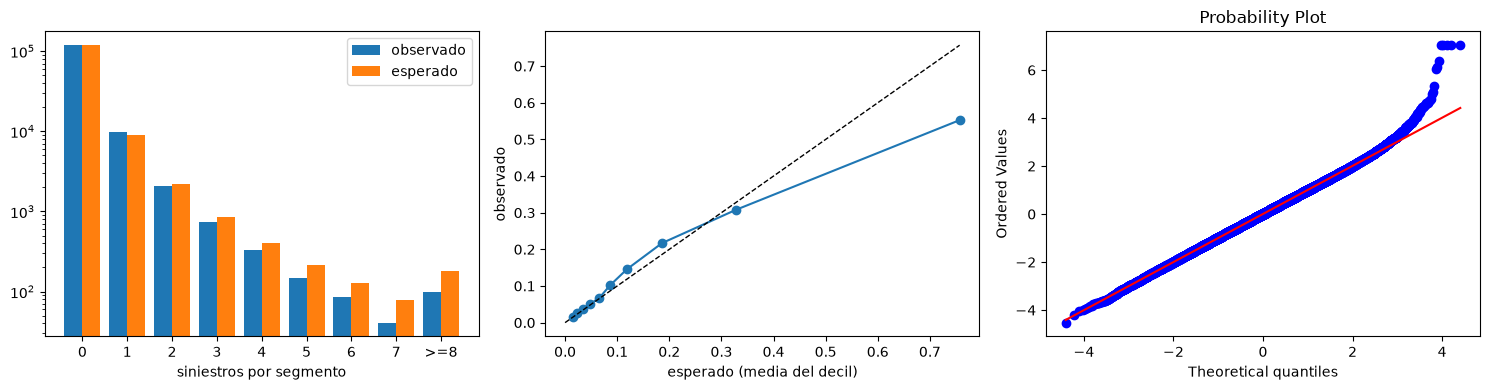

In [18]:
## Gráficos: conteos observados vs esperados (escala log), calibración y QQ de los residuos cuantílicos
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
pos = np.arange(len(freq))
ax[0].bar(pos - 0.2, freq['observado'], 0.4, label='observado')
ax[0].bar(pos + 0.2, freq['esperado'], 0.4, label='esperado')
ax[0].set_yscale('log'); ax[0].set_xticks(pos); ax[0].set_xticklabels(freq['conteo']); ax[0].set_xlabel('siniestros por segmento'); ax[0].legend()

ax[1].plot(calib['esperado'], calib['observado'], 'o-')
ax[1].plot([0, calib['esperado'].max()], [0, calib['esperado'].max()], 'k--', lw=1)
ax[1].set_xlabel('esperado (media del decil)'); ax[1].set_ylabel('observado')

stats.probplot(z, dist='norm', plot=ax[2])
plt.tight_layout()
plt.show()

## 10. Errores estándar robustos y coeficientes

In [19]:
## EE del modelo, robustos (HC0) y agrupados por celda espacial; con ZINB final se usa la BN como referencia de los EE
tipo_ee = MODELO_FINAL if MODELO_FINAL in ('Poisson', 'BN') else 'BN'
X, y, off = D['X_tr'], D['y_tr'], D['off_tr']
fam = sm.families.Poisson() if tipo_ee == 'Poisson' else sm.families.NegativeBinomial(alpha=aj['BN']['alpha'])    # alpha fijo: los EE no incluyen su incertidumbre
mod = sm.GLM(y, X, family=fam, offset=off)
f_mod, f_hc0, f_cl = mod.fit(), mod.fit(cov_type='HC0'), mod.fit(cov_type='cluster', cov_kwds={'groups': celda})

tab = pd.DataFrame({'coef': f_mod.params, 'EE modelo': f_mod.bse, 'EE HC0': f_hc0.bse, 'EE agrupado': f_cl.bse})
tab['IRR'] = np.exp(tab['coef'])
tab['IC95 inf'] = np.exp(tab['coef'] - 1.96 * tab['EE agrupado'])
tab['IC95 sup'] = np.exp(tab['coef'] + 1.96 * tab['EE agrupado'])
tab['p modelo'], tab['p agrupado'] = f_mod.pvalues, f_cl.pvalues
print(f"Modelo de los EE: {tipo_ee} | celdas (grupos): {len(np.unique(celda))}")
print(tab.round(4).to_string())

Modelo de los EE: BN | celdas (grupos): 132
                            coef  EE modelo  EE HC0  EE agrupado     IRR  IC95 inf  IC95 sup  p modelo  p agrupado
const                    -6.8581     0.0301  0.0349       0.0689  0.0011    0.0009    0.0012    0.0000      0.0000
dist_puente_peatonal_m    0.0124     0.0098  0.0116       0.0249  1.0124    0.9642    1.0631    0.2054      0.6201
dist_puente_vehicular_m   0.1124     0.0099  0.0120       0.0243  1.1190    1.0669    1.1737    0.0000      0.0000
dist_semaforo_m          -0.2265     0.0090  0.0105       0.0277  0.7973    0.7552    0.8418    0.0000      0.0000
ratio_cobertura_peatonal  0.7775     0.0123  0.0140       0.0257  2.1760    2.0691    2.2885    0.0000      0.0000
MVINUMC                   0.2075     0.0143  0.0185       0.0273  1.2306    1.1664    1.2984    0.0000      0.0000
vel_60                    0.3351     0.0246  0.0284       0.0566  1.3980    1.2512    1.5621    0.0000      0.0000


## 11. Sensibilidad: longitud como covariable libre en lugar de offset

In [20]:
## Se ajusta la BN con log(longitud) libre y con offset; el coeficiente de log_long mide la elasticidad (el offset supone 1)
D_o = armar_disenio(pos_all, pos_all, libre=False)
D_l = armar_disenio(pos_all, pos_all, libre=True)
bn_o = ajustar('bn', D_o['y_tr'], D_o['X_tr'], D_o['off_tr'], D_o['len_tr'])
bn_l = ajustar('bn', D_l['y_tr'], D_l['X_tr'], D_l['off_tr'], D_l['len_tr'])

f_l = sm.GLM(D_l['y_tr'], D_l['X_tr'], family=sm.families.NegativeBinomial(alpha=bn_l['alpha']), offset=D_l['off_tr']).fit(cov_type='cluster', cov_kwds={'groups': celda})
el, ic = f_l.params['log_long'], f_l.conf_int().loc['log_long']
print(f"Elasticidad con la longitud: {el:.3f} (IC95 % agrupado {ic[0]:.3f} a {ic[1]:.3f}); el offset supone 1.000")
LR_len = 2 * (bn_l['llf'] - bn_o['llf'])
print(f"logLik offset: {bn_o['llf']:.1f} | longitud libre: {bn_l['llf']:.1f} | LR = {LR_len:.1f} (1 gl, p = {stats.chi2.sf(LR_len, 1):.3g}) | alpha: {bn_o['alpha']:.3f} vs {bn_l['alpha']:.3f}")
print(pd.DataFrame({'IRR offset': np.exp(bn_o['res'].params), 'IRR longitud libre': np.exp(bn_l['res'].params.drop('log_long'))}).round(3).to_string())

Elasticidad con la longitud: 0.504 (IC95 % agrupado 0.461 a 0.547); el offset supone 1.000
logLik offset: -50374.5 | longitud libre: -49735.5 | LR = 1277.9 (1 gl, p = 7.02e-280) | alpha: 3.168 vs 2.830
                          IRR offset  IRR longitud libre
const                          0.001               0.057
dist_puente_peatonal_m         1.012               0.980
dist_puente_vehicular_m        1.119               1.082
dist_semaforo_m                0.797               0.781
ratio_cobertura_peatonal       2.176               2.022
MVINUMC                        1.231               1.238
vel_60                         1.398               1.414


In [21]:
## Validación por bloques de la especificación con longitud libre (solo Nulo, Poisson y BN) frente a la especificación con offset
cv_bloques_libre = validar(part_bloques, 'bloques, longitud libre', True, con_zinb=False)
cv_bloques_offset = validar(part_bloques, 'bloques, offset', False, con_zinb=False)
cmp_len = pd.concat([cv_bloques_offset, cv_bloques_libre]).query("modelo in ['Poisson', 'BN']").groupby(['esquema', 'modelo'])[['devianza', 'logscore', 'dev_explicada']].mean()
print(cmp_len.round(4).to_string())

bloques, longitud libre: pliegue 1/5 listo
bloques, longitud libre: pliegue 2/5 listo
bloques, longitud libre: pliegue 3/5 listo
bloques, longitud libre: pliegue 4/5 listo
bloques, longitud libre: pliegue 5/5 listo
bloques, offset: pliegue 1/5 listo
bloques, offset: pliegue 2/5 listo
bloques, offset: pliegue 3/5 listo
bloques, offset: pliegue 4/5 listo
bloques, offset: pliegue 5/5 listo
                                 devianza  logscore  dev_explicada
esquema                 modelo                                    
bloques, longitud libre BN         0.6073   -0.3781         0.1861
                        Poisson    0.6068   -0.4162         0.1868
bloques, offset         BN         0.6300   -0.3829         0.1557
                        Poisson    0.6255   -0.4255         0.1618
